# Phase 1: Retail Sales Data Understanding

Inspect the Rossmann training data, assess data quality, and document what should be understood before making cleaning or modeling decisions.

In [56]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PLOT_DIR = PROJECT_DIR / "plots" / "data understanding plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [34]:
train_path = PROJECT_DIR / "data" / "train.csv"
df = pd.read_csv(train_path)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype
---  ------         --------------    -----
 0   Store          1017209 non-null  int64
 1   DayOfWeek      1017209 non-null  int64
 2   Date           1017209 non-null  str  
 3   Sales          1017209 non-null  int64
 4   Customers      1017209 non-null  int64
 5   Open           1017209 non-null  int64
 6   Promo          1017209 non-null  int64
 7   StateHoliday   1017209 non-null  str  
 8   SchoolHoliday  1017209 non-null  int64
dtypes: int64(7), str(2)
memory usage: 69.8 MB


In [3]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,7/31/2015,5263,555,1,1,0,1
1,1,4,7/30/2015,5020,546,1,1,0,1
2,1,3,7/29/2015,4782,523,1,1,0,1
3,1,2,7/28/2015,5011,560,1,1,0,1
4,1,1,7/27/2015,6102,612,1,1,0,1


## Rossmann Training Columns

| Column | Meaning | Data interpretation |
| --- | --- | --- |
| `Store` | Store identifier | Categorical identifier, even though stored as an integer |
| `DayOfWeek` | Day of the week | Integer from 1 (Monday) to 7 (Sunday) |
| `Date` | Observation date | Convert to a datetime value for calendar analysis |
| `Sales` | Sales for that store and day | Prediction target; source units are not specified here |
| `Customers` | Customer count for that store and day | Daily count; useful for exploration, but may not be available when forecasting |
| `Open` | Whether the store was open | 0 = closed, 1 = open |
| `Promo` | Whether a promotion was active | 0 = no, 1 = yes |
| `StateHoliday` | State holiday type | `0` = no holiday, `a` = public holiday, `b` = Easter, `c` = Christmas |
| `SchoolHoliday` | Whether schools were closed | 0 = no, 1 = yes |

The separate `store.csv` file contains store-level attributes; it is not part of the training table loaded below.

In [52]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:", list(df.columns))

Rows: 1017209
Columns: 9
Column names: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


In [7]:
df.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [25]:
df.dtypes

Store                     int64
DayOfWeek                 int64
Date             datetime64[us]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday                str
SchoolHoliday             int64
dtype: object

## Data Types and Date Parsing

Check the raw types, then convert `Date` from text to datetime so calendar features and time-based checks work correctly.

In [35]:
df["Date"] = pd.to_datetime(df["Date"])

## Missing Values

Count missing entries and calculate their share of the dataset. A zero is not automatically missing; its meaning depends on the column.

In [45]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100),
})
missing_summary

,missing_count,missing_percent
Store,0,0.0
DayOfWeek,0,0.0
Date,0,0.0
Sales,0,0.0
Customers,0,0.0
Open,0,0.0
Promo,0,0.0
StateHoliday,0,0.0
SchoolHoliday,0,0.0


## Duplicate Records

Check exact duplicate rows and duplicate `Store` + `Date` pairs separately. A store should normally have at most one daily training record.

In [28]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# df[df.duplicated()]

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


In [51]:
store_date_duplicates = df.duplicated(subset=["Store", "Date"]).sum()
print("Duplicate Store-Date records:", store_date_duplicates)

Duplicate Store-Date records: 0


## Unique Values

Inspect identifiers, binary flags, weekday codes, and holiday categories to confirm the observed values match their documented meanings.

In [38]:
df["Store"].nunique() #Number of unique stores


1115

In [39]:
df["DayOfWeek"].unique() #Number of unique days of the week


array([5, 4, 3, 2, 1, 7, 6])

In [40]:
df["Promo"].unique() #Number of unique promo values


array([1, 0])

In [41]:
df["StateHoliday"].unique() #Number of unique state holiday values


<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

In [42]:
df["SchoolHoliday"].unique() #Number of unique school holiday values

array([1, 0])

In [43]:
df["StateHoliday"].value_counts()

StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64

## Value Validity

Look for impossible negative values and inspect numeric ranges. Treat suspicious observations as investigation targets, not automatic deletion candidates.

In [ ]:
(df["Sales"]<0).sum() #Where sales are negative

np.int64(0)

In [ ]:
(df["Customers"]<0).sum() #checking for negative customers

np.int64(0)

In [50]:
min=df["Customers"].min()
max=df["Customers"].max()
print(f"Minimum Customers:{min}, Maximum Customers: {max}")

Minimum Customers:0, Maximum Customers: 7388


In [46]:
(df["Store"]<0).sum()

np.int64(0)

In [48]:
min=df["Sales"].min()
max=df["Sales"].max()
print(f"Minimum Sales:{min}, Maximum Sales: {max}")

Minimum Sales:0, Maximum Sales: 41551


## Store Opening Behavior

Compare sales for open and closed records. Keep the original dataframe intact; the separate open-store view is only for answering questions about operating-store sales.

In [53]:
df.groupby("Open")["Sales"].agg(["count", "mean", "median"])

,count,mean,median
Open,,,
0,172817,0.000000,0.0
1,844392,6955.514291,6369.0


In [54]:
open_store_rows = df.loc[df["Open"].eq(1)].copy()
print("Rows where the store was open:", len(open_store_rows))
print("The original df still contains all rows:", len(df))

Rows where the store was open: 844392
The original df still contains all rows: 1017209


## Relationships and Store Comparisons

Question 1

Does having more customers generally mean higher sales?

In [9]:
df[["Customers", "Sales"]].corr()

,Customers,Sales
Customers,1.000000,0.894711
Sales,0.894711,1.000000


This suggest a strong positive relationship.

But don't automatically conclude:

"Customers cause sales."

Correlation doesn't establish causation.

### Promotion and Average Sales

Compare daily averages descriptively; this does not isolate the causal effect of promotions.

In [55]:
df.groupby("Promo")["Sales"].mean()

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64

Now we have something interesting to investigate.

Question 3

Which stores generate the most sales?

In [21]:
# df.groupby("Store")["Sales"].sum().sort_values(ascending=False)
df.groupby("Store")["Sales"].mean().sort_values(ascending=False)

Store
262     20718.515924
817     18108.139066
562     17969.556263
1114    17200.196391
251     15814.087049
            ...     
841      2461.395966
208      2443.791932
198      2407.933121
543      2313.468153
307      2244.503185
Name: Sales, Length: 1115, dtype: float64

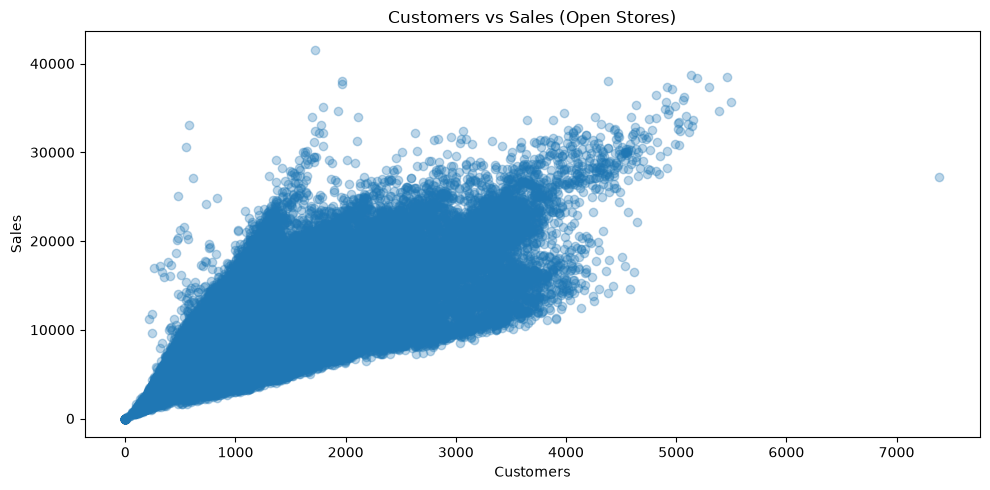

In [60]:
plt.figure(figsize=(10, 5))
plt.scatter(
    open_store_rows["Customers"],
    open_store_rows["Sales"],
    alpha=0.3,
)
plt.xlabel("Customers")
plt.ylabel("Sales")
plt.title("Customers vs Sales (Open Stores)")
plt.tight_layout()
plt.savefig(PLOT_DIR / "customers_vs_sales.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## Target Variable: Sales

Review the sales distribution and summary statistics. `Sales` is the intended prediction target; no feature matrix is created in this phase.

In [10]:
df["Sales"].info()

<class 'pandas.Series'>
RangeIndex: 1017209 entries, 0 to 1017208
Series name: Sales
Non-Null Count    Dtype
--------------    -----
1017209 non-null  int64
dtypes: int64(1)
memory usage: 7.8 MB


In [11]:
df["Sales"].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

In [12]:
print("Mean:", df["Sales"].mean())
print("Median:", df["Sales"].median())
print("Minimum:", df["Sales"].min())
print("Maximum:", df["Sales"].max())
print("Standard deviation:", df["Sales"].std())

Mean: 5773.818972305593
Median: 5744.0
Minimum: 0
Maximum: 41551
Standard deviation: 3849.9261752347597


15. Check sales distribution

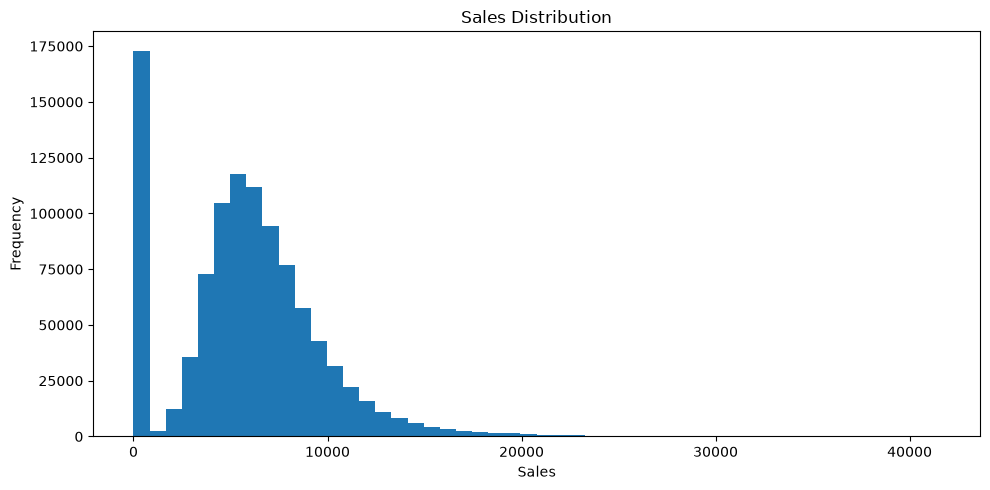

In [63]:
plt.figure(figsize=(10, 5))
plt.hist(df["Sales"], bins=50)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Sales Distribution")
plt.tight_layout()
plt.savefig(PLOT_DIR / "sales_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

16. Detect outliers

In [43]:
q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

sales_outliers = df.loc[
    df["Sales"].lt(lower_bound) | df["Sales"].gt(upper_bound),
    ["Store", "Date", "Sales", "Customers", "Open", "Promo"],
]

print(f"Q1: {q1:,.2f}")
print(f"Q3: {q3:,.2f}")
print(f"IQR: {iqr:,.2f}")
print(f"Lower bound: {lower_bound:,.2f}")
print(f"Upper bound: {upper_bound:,.2f}")
print("Potential sales outliers:", len(sales_outliers))
sales_outliers.head(10)

Q1: 3,727.00
Q3: 7,856.00
IQR: 4,129.00
Lower bound: -2,466.50
Upper bound: 14,049.50
Potential sales outliers: 26694


,Store,Date,Sales,Customers,Open,Promo
2280,3,2014-06-30,15689,1193,1,1
2469,3,2013-12-23,14461,1579,1,0
2475,3,2013-12-17,14555,1284,1,1
2476,3,2013-12-16,14647,1282,1,1
2918,4,2015-04-30,16106,1854,1,1
2944,4,2015-04-04,15018,1917,1,0
2946,4,2015-04-02,17311,1976,1,1
2948,4,2015-03-31,14451,1724,1,1
3039,4,2014-12-30,16860,2075,1,0
3046,4,2014-12-23,15839,2071,1,0


IQR flags unusually high or low values relative to the overall distribution; it does not prove they are errors. Check dates, promotions, customer counts, and store context before deciding whether any record needs correction.

Check outliers visually

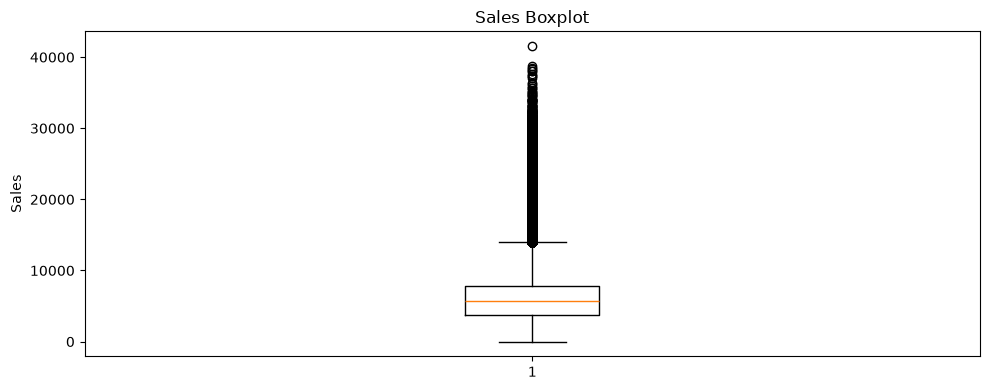

In [64]:
plt.figure(figsize=(10, 4))
plt.boxplot(df["Sales"].dropna())
plt.ylabel("Sales")
plt.title("Sales Boxplot")
plt.tight_layout()
plt.savefig(PLOT_DIR / "sales_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

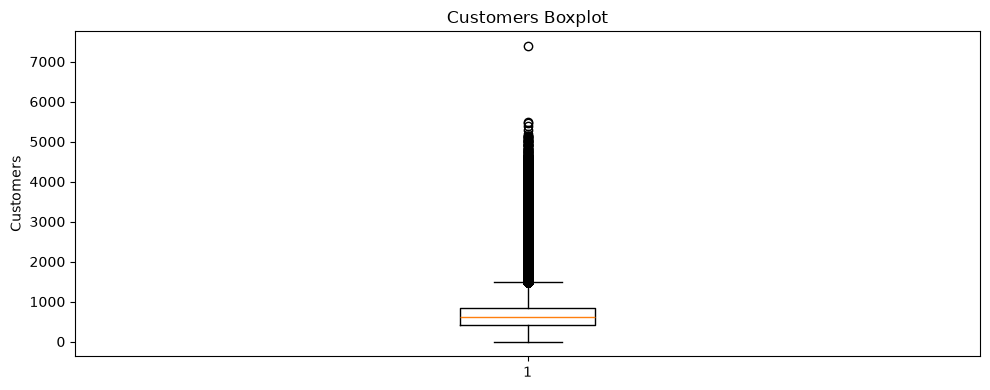

In [65]:
plt.figure(figsize=(10, 4))
plt.boxplot(df["Customers"].dropna())
plt.ylabel("Customers")
plt.title("Customers Boxplot")
plt.tight_layout()
plt.savefig(PLOT_DIR / "customers_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

19. Check correlations

In [47]:
correlation_columns = ["Sales", "Customers", "Open", "Promo", "SchoolHoliday"]
correlation = df[correlation_columns].corr()
correlation

,Sales,Customers,Open,Promo,SchoolHoliday
Sales,1.000000,0.894711,0.678472,0.452345,0.085124
Customers,0.894711,1.000000,0.616768,0.316169,0.071568
Open,0.678472,0.616768,1.000000,0.295042,0.086171
Promo,0.452345,0.316169,0.295042,1.000000,0.067483
SchoolHoliday,0.085124,0.071568,0.086171,0.067483,1.000000


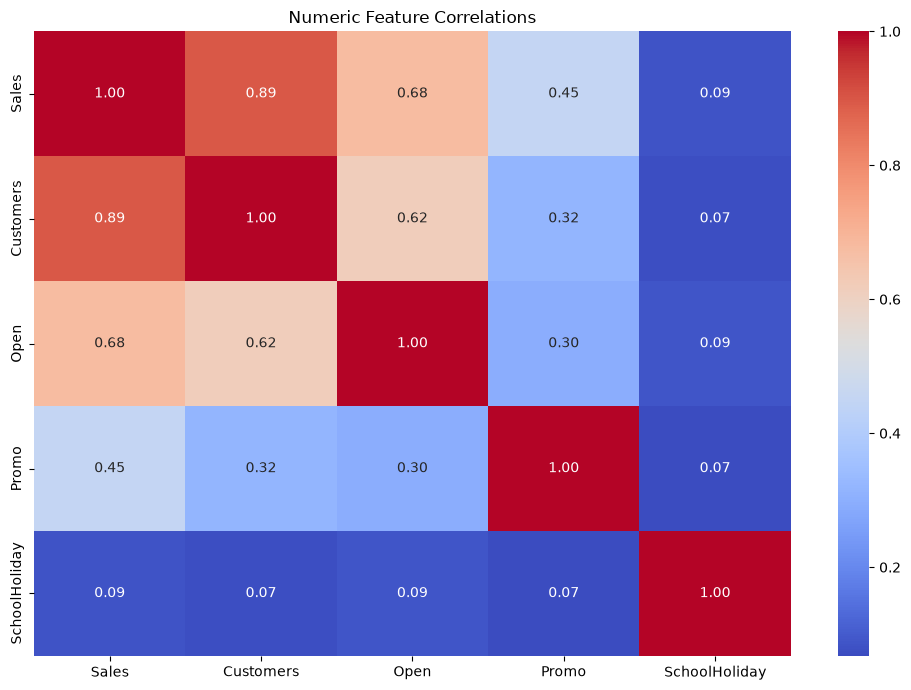

In [66]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numeric Feature Correlations")
plt.tight_layout()
plt.savefig(PLOT_DIR / "numeric_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [46]:
print("===== DATASET SUMMARY =====")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSales statistics:")
print(df["Sales"].describe())

print("\nCustomers statistics:")
print(df["Customers"].describe())

===== DATASET SUMMARY =====
Rows: 1017209
Columns: 9

Missing values:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Duplicate rows:
0

Sales statistics:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Customers statistics:
count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64
